In [24]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
iris_df = iris.frame
Xc = iris_df.drop(columns=["target"])
yc = iris.target
print(Xc.head())
print(iris.target_names)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
['setosa' 'versicolor' 'virginica']


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pltfrom 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
Xtr, Xte, ytr, yte = train_test_split(
    Xc, yc, test_size=0.2,
    random_state=42, stratify=yc
)
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
log_model.fit(Xtr, ytr)
pred_log = log_model.predict(Xte)
print(pred_log[:10])


[0 2 1 1 0 1 0 0 2 1]


In [26]:
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=7)
)
knn.fit(Xtr, ytr)
pred_knn = knn.predict(Xte)
print(pred_knn[:7])

[0 2 1 1 0 1 0]


In [27]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(Xtr, ytr)
pred_nb = nb.predict(Xte)
print(pred_nb[:10])


[0 2 1 1 0 1 0 0 2 1]


[Text(0.375, 0.875, 'petal length (cm) <= 2.45\ngini = 0.667\nsamples = 120\nvalue = [40, 40, 40]\nclass = setosa'),
 Text(0.25, 0.625, 'gini = 0.0\nsamples = 40\nvalue = [40, 0, 0]\nclass = setosa'),
 Text(0.3125, 0.75, 'True  '),
 Text(0.5, 0.625, 'petal width (cm) <= 1.65\ngini = 0.5\nsamples = 80\nvalue = [0, 40, 40]\nclass = versicolor'),
 Text(0.4375, 0.75, '  False'),
 Text(0.25, 0.375, 'petal length (cm) <= 4.95\ngini = 0.133\nsamples = 42\nvalue = [0, 39, 3]\nclass = versicolor'),
 Text(0.125, 0.125, 'gini = 0.0\nsamples = 38\nvalue = [0, 38, 0]\nclass = versicolor'),
 Text(0.375, 0.125, 'gini = 0.375\nsamples = 4\nvalue = [0, 1, 3]\nclass = virginica'),
 Text(0.75, 0.375, 'petal length (cm) <= 4.85\ngini = 0.051\nsamples = 38\nvalue = [0, 1, 37]\nclass = virginica'),
 Text(0.625, 0.125, 'gini = 0.444\nsamples = 3\nvalue = [0, 1, 2]\nclass = virginica'),
 Text(0.875, 0.125, 'gini = 0.0\nsamples = 35\nvalue = [0, 0, 35]\nclass = virginica')]

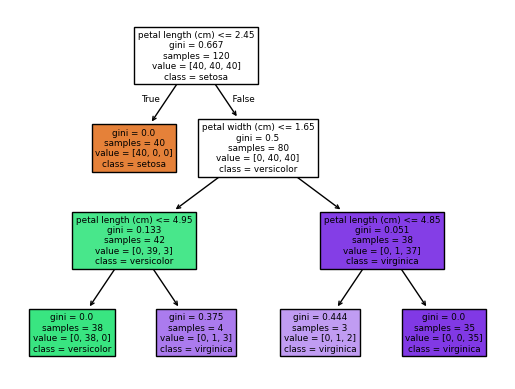

In [28]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree = DecisionTreeClassifier(
    max_depth=3, random_state=42
)
tree.fit(Xtr, ytr)
pred_tree = tree.predict(Xte)
plot_tree(tree, feature_names=Xc.columns,
          class_names=iris.target_names,
          filled=True)

In [29]:
from sklearn.svm import SVC
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)
svm.fit(Xtr, ytr)
pred_svm = svm.predict(Xte)
print(pred_svm[:10])

[0 2 1 1 0 1 0 0 2 1]


In [30]:
# Demonstration with a binary company
# churn dataset after preparing X_train, y_train.
from sklearn.linear_model import LogisticRegression
weighted = LogisticRegression(
    class_weight="balanced",
    max_iter=2000
)
# Fit after applying the same
# preprocessing pipeline to X_train.
print("Balanced class weights enabled")

Balanced class weights enabled


In [31]:
import pandas as pd
from imblearn.over_sampling import SMOTE

X_train_encoded = pd.get_dummies(Xtr, drop_first=True)

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train_encoded, ytr)

print("Before:", pd.Series(ytr).value_counts())
print("After:", pd.Series(y_res).value_counts())

Before: target
0    40
2    40
1    40
Name: count, dtype: int64
After: target
0    40
2    40
1    40
Name: count, dtype: int64


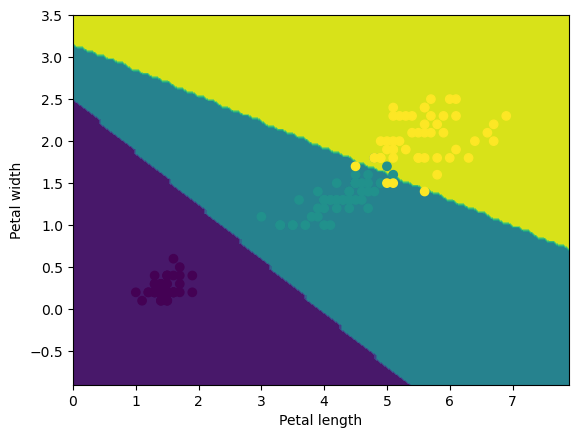

In [32]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
X2 = Xc[["petal length (cm)",
         "petal width (cm)"]]
boundary_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
boundary_model.fit(X2, yc)
DecisionBoundaryDisplay.from_estimator(
    boundary_model, X2,
    response_method="predict",
    plot_method="contourf"
)
plt.scatter(X2.iloc[:,0], X2.iloc[:,1], c=yc)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.show()


In [33]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Split the dataset
Xtr, Xte, ytr, yte = train_test_split(
    Xc, yc,
    test_size=0.2,
    random_state=42,
    stratify=yc
)

# Apply SMOTE
print("Before:")
print(ytr.value_counts())

smote = SMOTE(random_state=42)

X_res, y_res = smote.fit_resample(Xtr, ytr)

print("After:")
print(pd.Series(y_res).value_counts())

Before:
target
0    40
2    40
1    40
Name: count, dtype: int64
After:
target
0    40
2    40
1    40
Name: count, dtype: int64


In [34]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
print("Accuracy:", accuracy_score(yte,pred_log))
print("Precision:", precision_score(
    yte,pred_log,average="weighted"))
print("Recall:", recall_score(
    yte,pred_log,average="weighted"))
print("F1:", f1_score(
    yte,pred_log,average="weighted"))

Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1: 0.9333333333333333


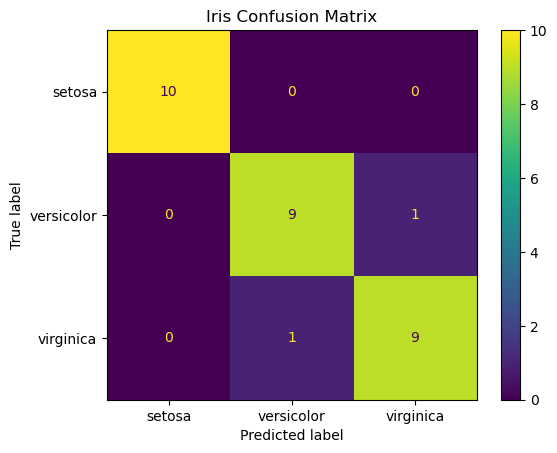

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(
    yte, pred_log,
    display_labels=iris.target_names
)
plt.title("Iris Confusion Matrix")
plt.show()

In [36]:
# Binary example: positive class is 1
from sklearn.metrics import RocCurveDisplay, roc_auc_score
# Fit a binary classifier that supports predict_proba.
# y_binary must contain 0 and 1.
# probabilities = model.predict_proba(X_test)[:, 1]
# RocCurveDisplay.from_predictions(
#     y_binary, probabilities
# )
# print("ROC-AUC:",
#       roc_auc_score(y_binary, probabilities))
# plt.show()

In [37]:
from sklearn.metrics import accuracy_score, f1_score
models = {
 "Logistic": log_model,
 "KNN": knn,
 "Naive Bayes": nb,
 "Decision Tree": tree,
 "SVM": svm
}
for name, model in models.items():
    pred = model.predict(Xte)
    print(name,
          "Accuracy:", round(accuracy_score(yte,pred),3),
          "F1:", round(f1_score(yte,pred,average="weighted"),3))

Logistic Accuracy: 0.933 F1: 0.933
KNN Accuracy: 0.967 F1: 0.967
Naive Bayes Accuracy: 0.967 F1: 0.967
Decision Tree Accuracy: 0.967 F1: 0.967
SVM Accuracy: 0.967 F1: 0.967


In [38]:
from sklearn.datasets import load_iris
iris = load_iris()
from sklearn.metrics import accuracy_score
print("Classes:", iris.target_names)
print("Logistic accuracy:",
      accuracy_score(yte, pred_log))
print("Tree accuracy:",
      accuracy_score(yte, pred_tree))

Classes: ['setosa' 'versicolor' 'virginica']
Logistic accuracy: 0.9333333333333333
Tree accuracy: 0.9666666666666667
